
#**Netflix Movies and TV Shows: Independent Data Exploration**

##*Project Overview*

Netflix offers movies and television shows from different countries, genres, time periods, and audience categories. This project explores a Netflix catalog dataset to better understand the characteristics and composition of its content.

The analysis focuses on data cleaning, exploratory data analysis, statistical analysis, missing values, outliers, and visualization.

##*Research Questions*

1. What proportion of the catalog consists of movies versus TV shows?
2. How has the number of titles added to Netflix changed over time?
3. Which countries contribute the most content?
4. Which genres appear most frequently?
5. Which audience ratings are most common?
6. What does the distribution of movie duration look like?
7. Are there differences in movie duration across major genres?
8. How long after release are titles typically added to Netflix?


# 1. Setup and Load Data

First, I import the Python libraries needed for data manipulation, statistical analysis, and visualization.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


## Dataset Source

The dataset was obtained from Kaggle and contains information about Netflix movies and TV shows, including title, content type, country, release year, date added, rating, duration, genre, cast, director, and description.

In [4]:
from google.colab import files
uploaded = files.upload()


Saving netflix_titles.csv to netflix_titles.csv


In [8]:
df = uploaded

In [5]:
df = pd.read_csv("netflix_titles.csv")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
df.head()


Rows: 8,807
Columns: 12


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


# 2. Initial Data Exploration

Before performing data cleaning and preprocessing, an initial exploration of the dataset was conducted to understand its structure and quality. This included examining the dataset dimensions, data types, summary statistics, duplicate records, and missing values.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8807,8807,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8807,Dick Johnson Is Dead,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,6173,4528,Rajiv Chilaka,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7982,7692,David Attenborough,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7976,748,United States,2818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8797,1767,"January 1, 2020",109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8803,17,TV-MA,3207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8804,220,1 Season,1793,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["show_id"].duplicated().sum())


Dataset shape: (8807, 12)
Duplicate rows: 0
Duplicate IDs: 0


### Initial Observations

The dataset contains both categorical and numerical variables. Most fields are stored as text. The `release_year` field is numeric, while `date_added` and `duration` require additional transformation before analysis.

Some descriptive fields, particularly `director`, `cast`, and `country`, contain missing values.

# 3. Missing-Value Analysis

Missing data can influence analytical results. I calculated both the number and percentage of missing values for each column before deciding how to handle them.

In [9]:
missing = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().mean() * 100).round(2)
})
missing = missing.sort_values(
    "Missing_Percent",
    ascending=False
)
missing


,Missing_Count,Missing_Percent
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03
show_id,0,0.00
type,0,0.00
title,0,0.00
release_year,0,0.00


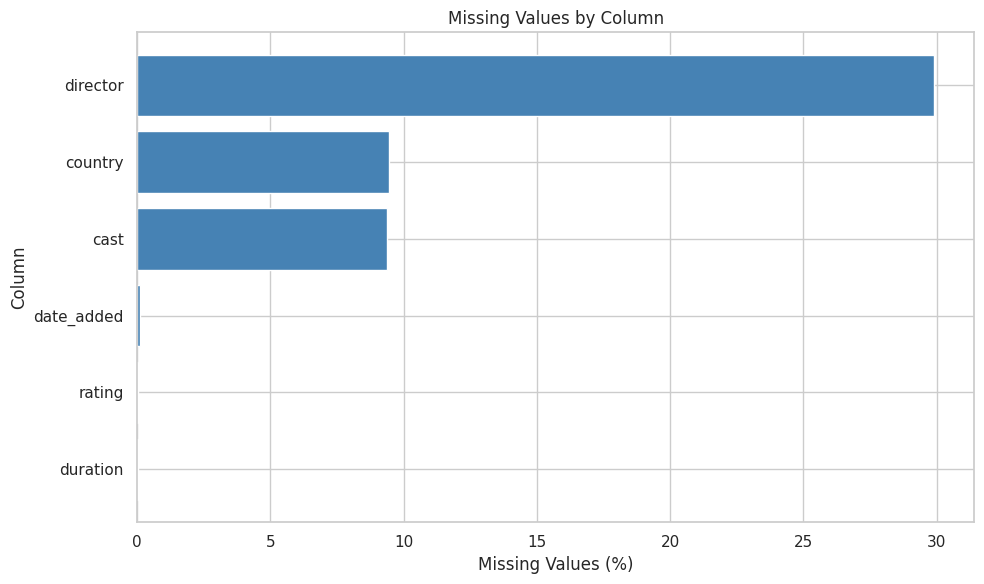

In [10]:
missing_plot = missing[
    missing["Missing_Count"] > 0
].sort_values("Missing_Percent")
plt.figure(figsize=(10, 6))
plt.barh(
    missing_plot.index,
    missing_plot["Missing_Percent"],
    color="steelblue"
)
plt.title("Missing Values by Column")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.show()


### Interpretation

Missing values are concentrated primarily in descriptive fields such as `director`, `cast`, and `country`. Rather than removing these records, the missing values were retained because the same observations still contain useful information about release year, genre, rating, duration, and content type.

Where appropriate, missing descriptive values will be categorized as `"Unknown"` to preserve records while maintaining consistency in the analysis.

# 4. Data Cleaning

The dataset was cleaned through several preprocessing steps to improve data quality and ensure consistency for analysis.

The following actions were performed:

- Standardized column names
- Removed duplicate records
- Eliminated unnecessary whitespace from text fields
- Handled missing categorical values
- Converted date fields to the appropriate data type
- Transformed duration values into numerical format
- Created additional variables to support analysis

In [11]:
# Create a copy so the original dataset remains unchanged
netflix = df.copy()
# Standardize column names
netflix.columns = (
    netflix.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)
# Remove whitespace from text fields
text_columns = netflix.select_dtypes(include="object").columns
for column in text_columns:
    netflix[column] = netflix[column].str.strip()
# Remove duplicates
netflix = netflix.drop_duplicates()
netflix = netflix.drop_duplicates(
    subset="show_id",
    keep="first"
)
print("Cleaned dataset shape:", netflix.shape)


Cleaned dataset shape: (8807, 12)


In [13]:
#Handle missing values:
for column in ["director", "cast", "country"]:
    netflix[column] = netflix[column].fillna("Unknown")


In [14]:
#Convert dates:
netflix["date_added"] = pd.to_datetime(
    netflix["date_added"],
    errors="coerce"
)
netflix["year_added"] = (
    netflix["date_added"]
    .dt.year
    .astype("Int64")
)
netflix["month_added"] = netflix["date_added"].dt.month_name()


In [15]:
#Create numeric duration variables:
netflix["duration_value"] = pd.to_numeric(
    netflix["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)
netflix["movie_minutes"] = np.where(
    netflix["type"] == "Movie",
    netflix["duration_value"],
    np.nan
)
netflix["tv_seasons"] = np.where(
    netflix["type"] == "TV Show",
    netflix["duration_value"],
    np.nan
)


In [16]:
#Create analytical columns:
# Primary country
netflix["primary_country"] = (
    netflix["country"]
    .str.split(",")
    .str[0]
    .str.strip()
)
# Primary genre
netflix["primary_genre"] = (
    netflix["listed_in"]
    .str.split(",")
    .str[0]
    .str.strip()
)
# Age of content when added to Netflix
netflix["content_age_at_addition"] = (
    netflix["year_added"] -
    netflix["release_year"]
)
# Treat impossible negative ages as missing
netflix.loc[
    netflix["content_age_at_addition"] < 0,
    "content_age_at_addition"
] = np.nan


### Cleaning Decisions

Missing values in the `director`, `cast`, and `country` columns were retained rather than removing the corresponding records. This approach minimizes unnecessary data loss while preserving valuable information contained in other variables.

Movie and TV show durations were separated because they represent fundamentally different measurements. Movie duration is measured in minutes, whereas TV show duration is measured in seasons.

For geographic and genre-based analyses, primary country and primary genre variables were created using the first listed value in each record. Where appropriate, genre-related analyses also consider all assigned genres to provide a more comprehensive view of content distribution.

# 5. Descriptive Statistical Analysis

Descriptive statistics were calculated to understand the distribution, central tendency, and variability of important numerical variables.

In [17]:
netflix[
    [
        "release_year",
        "movie_minutes",
        "tv_seasons",
        "content_age_at_addition"
    ]
].describe().round(2)


,release_year,movie_minutes,tv_seasons,content_age_at_addition
count,8807.00,6128.00,2676.00,8783.0
mean,2014.18,99.58,1.76,4.7
std,8.82,28.29,1.58,8.79
min,1925.00,3.00,1.00,0.0
25%,2013.00,87.00,1.00,0.0
50%,2017.00,98.00,1.00,1.0
75%,2019.00,114.00,2.00,5.0
max,2021.00,312.00,17.00,93.0


In [18]:
type_summary = netflix["type"].value_counts().to_frame("Count")
type_summary["Percentage"] = (
    netflix["type"].value_counts(normalize=True) * 100
).round(2)
type_summary


,Count,Percentage
type,,
Movie,6131,69.62
TV Show,2676,30.38


In [19]:
movie_stats = netflix.loc[
    netflix["type"] == "Movie",
    "movie_minutes"
].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
])
movie_stats.round(2)


,movie_minutes
count,6128.00
mean,99.58
median,98.00
std,28.29
min,3.00
max,312.00


### Statistical Interpretation

The descriptive statistics provide insights into key numerical variables, including release year, movie duration, TV show seasons, and the age of content when added to Netflix.

Both the mean and median were examined to better understand typical values within the dataset. Because extreme values can influence the mean, the median serves as a more robust measure of central tendency when outliers are present.

Comparing these measures also helps identify potential skewness in the distribution of variables such as movie duration and content age.

# 6. Outlier Analysis

Movie duration was selected as an appropriate continuous variable for outlier detection. The Interquartile Range (IQR) method was used to identify unusually short or long movies.

A value is considered a potential outlier if it falls:

- Below: **Q1 − 1.5 × IQR**
- Above: **Q3 + 1.5 × IQR**

where:

- **Q1** = First Quartile (25th percentile)
- **Q3** = Third Quartile (75th percentile)
- **IQR** = Q3 − Q1

In [20]:
movie_data = netflix[
    (netflix["type"] == "Movie") &
    (netflix["movie_minutes"].notna())
].copy()
Q1 = movie_data["movie_minutes"].quantile(0.25)
Q3 = movie_data["movie_minutes"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
movie_data["duration_outlier"] = (
    (movie_data["movie_minutes"] < lower_bound) |
    (movie_data["movie_minutes"] > upper_bound)
)
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print(
    "Number of Outliers:",
    movie_data["duration_outlier"].sum()
)


Q1: 87.0
Q3: 114.0
IQR: 27.0
Lower Bound: 46.5
Upper Bound: 154.5
Number of Outliers: 450


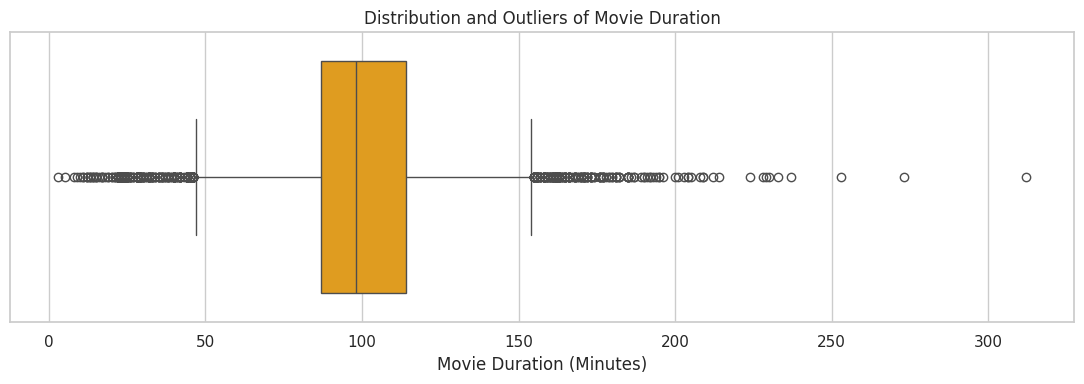

In [21]:
plt.figure(figsize=(11, 4))
sns.boxplot(
    data=movie_data,
    x="movie_minutes",
    color="orange"
)
plt.title("Distribution and Outliers of Movie Duration")
plt.xlabel("Movie Duration (Minutes)")
plt.tight_layout()
plt.show()


### Outlier Decision

The IQR method identified movies with unusually short or long durations. However, these observations were retained in the dataset.

An extreme duration does not necessarily indicate an error in the data. Short films, documentaries, special features, and extended productions may legitimately fall outside the typical duration range.

Therefore, outliers were identified and examined but were not automatically removed, as they may represent meaningful and valid content within the Netflix catalog.

# 7. Exploratory Data Analysis

The following visualizations and analyses address the research questions introduced at the beginning of the project. Exploratory Data Analysis (EDA) is used to identify patterns, trends, relationships, and insights within the Netflix dataset.

The visualizations focus on content distribution, release trends, geographic representation, genres, ratings, duration characteristics, and other key features of the Netflix catalog.

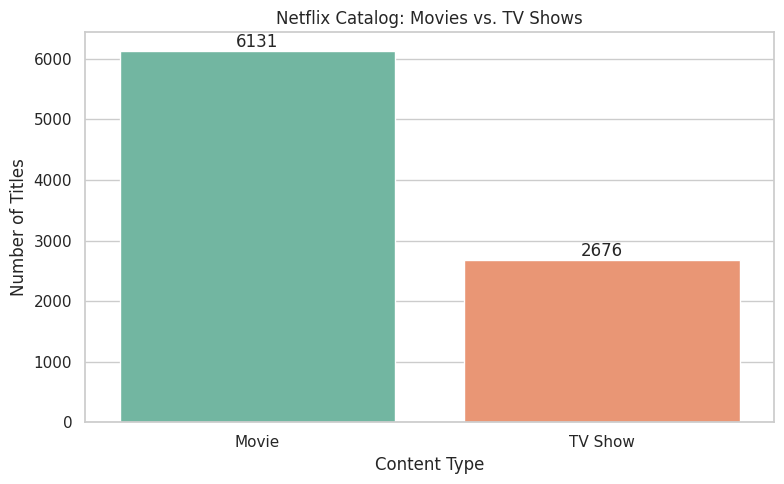

In [22]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(
    data=netflix,
    x="type",
    hue="type",
    palette="Set2",
    legend=False
)
plt.title("Netflix Catalog: Movies vs. TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()


### Finding

Movies represent a substantially larger share of the Netflix catalog than TV shows. This indicates that Netflix's content library is more heavily populated with movies than episodic content.

However, this finding describes only the composition of the available catalog and should not be interpreted as evidence of viewer preferences, engagement levels, or viewing behavior.

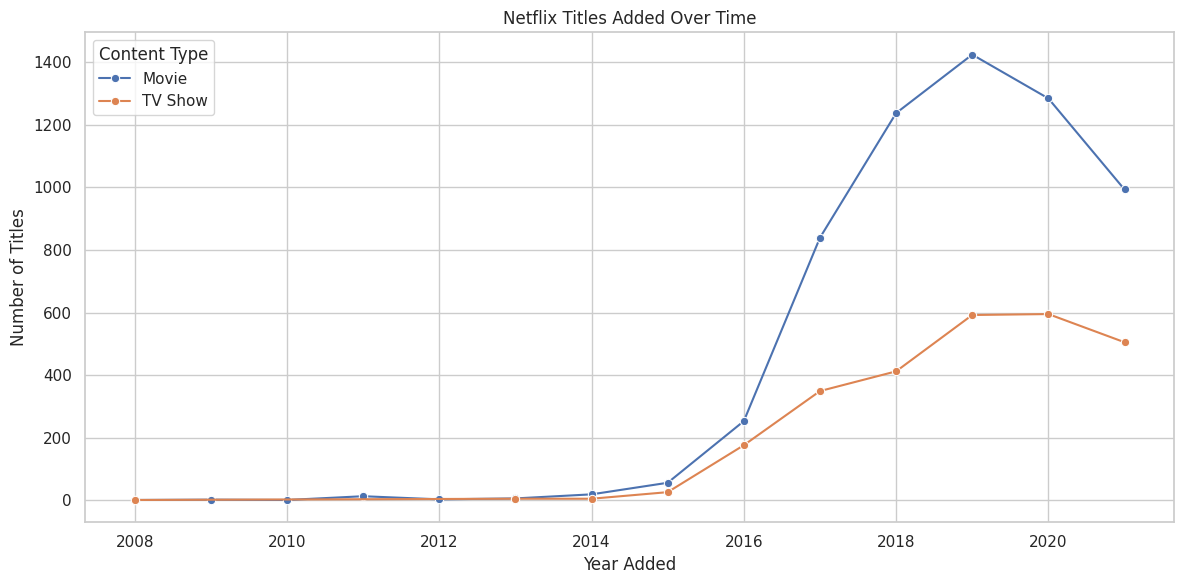

In [23]:
titles_by_year = (
    netflix
    .dropna(subset=["year_added"])
    .groupby(["year_added", "type"])
    .size()
    .reset_index(name="title_count")
)
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=titles_by_year,
    x="year_added",
    y="title_count",
    hue="type",
    marker="o"
)
plt.title("Netflix Titles Added Over Time")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()


### Finding

The number of titles added to Netflix increased substantially during the later years represented in the dataset. This growth suggests a significant expansion of the Netflix content library over time.

Movies generally accounted for a larger share of yearly additions than TV shows, contributing most of the growth observed in the catalog.

The final year in the dataset should be interpreted with caution because it may represent only a partial year of data. Consequently, lower counts in the final year may reflect incomplete data collection rather than a true decline in content additions.

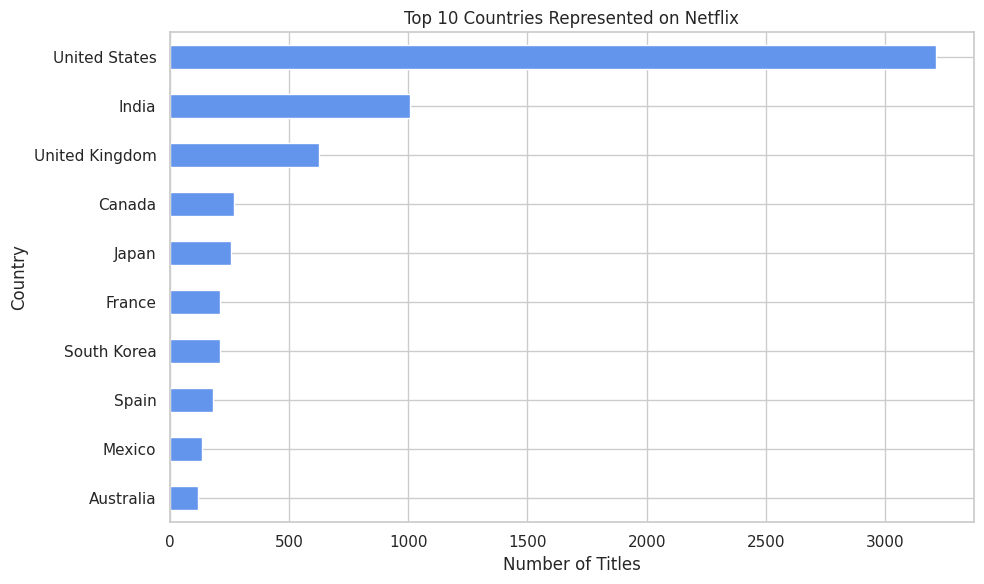

In [24]:
top_countries = (
    netflix[
        netflix["primary_country"] != "Unknown"
    ]["primary_country"]
    .value_counts()
    .head(10)
    .sort_values()
)
plt.figure(figsize=(10, 6))
top_countries.plot(
    kind="barh",
    color="cornflowerblue"
)
plt.title("Top 10 Countries Represented on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


### Finding

Although Netflix offers content from a wide range of countries, a large proportion of titles originate from a relatively small number of countries. The United States and India are among the most prominent contributors to the Netflix catalog.

This pattern suggests that content production and distribution within the dataset are concentrated in a few major entertainment markets, while many other countries contribute smaller numbers of titles.

For consistency, titles associated with multiple countries were assigned a `primary_country` based on the first listed country. Therefore, the visualization reflects primary country attribution rather than all country associations.

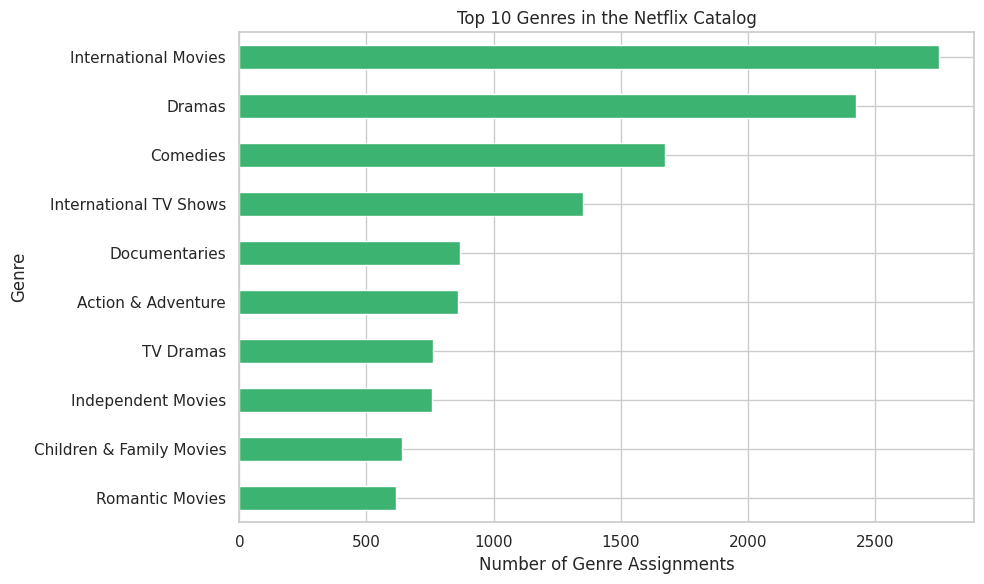

In [25]:
genre_counts = (
    netflix["listed_in"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
    .sort_values()
)
plt.figure(figsize=(10, 6))
genre_counts.plot(
    kind="barh",
    color="mediumseagreen"
)
plt.title("Top 10 Genres in the Netflix Catalog")
plt.xlabel("Number of Genre Assignments")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()


### Finding

The genre analysis highlights the categories that appear most frequently within the Netflix catalog. The results provide insight into the types of content that are most commonly available on the platform.

Because a single title can belong to multiple genres, this analysis counts genre assignments rather than treating genres as mutually exclusive categories. As a result, the total number of genre occurrences may exceed the total number of titles in the dataset.

The findings indicate which content categories dominate the catalog and help reveal the diversity of genres offered to viewers.

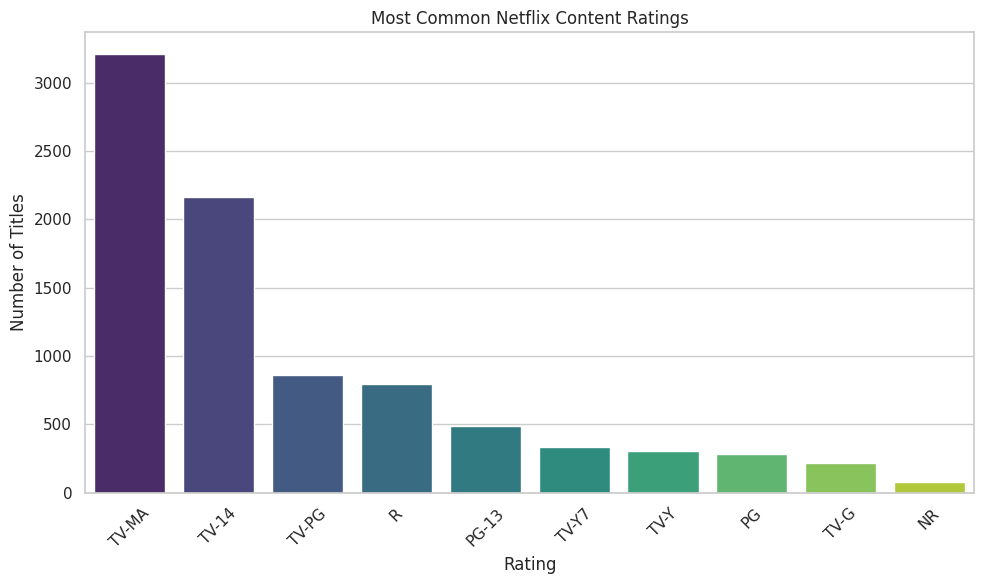

In [26]:
top_ratings = netflix["rating"].value_counts().head(10)
plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_ratings.index,
    y=top_ratings.values,
    hue=top_ratings.index,
    palette="viridis",
    legend=False
)
plt.title("Most Common Netflix Content Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Finding

The most common ratings provide insight into the audience categories represented in the catalog. Ratings intended for mature and teenage audiences are strongly represented compared with several younger-audience rating categories.


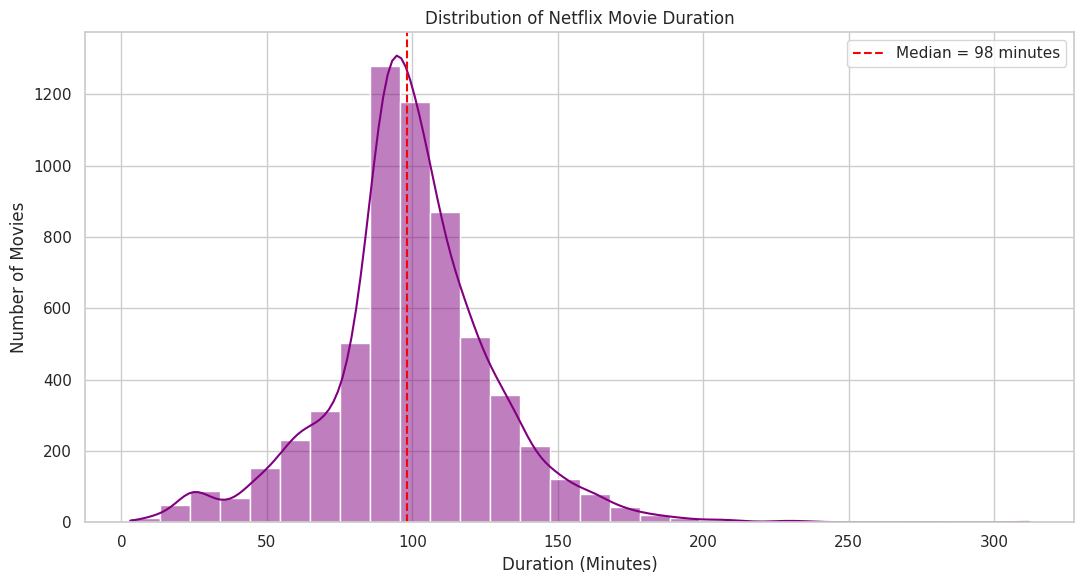

In [27]:
plt.figure(figsize=(11, 6))
sns.histplot(
    data=movie_data,
    x="movie_minutes",
    bins=30,
    kde=True,
    color="purple"
)
median_duration = movie_data["movie_minutes"].median()
plt.axvline(
    median_duration,
    color="red",
    linestyle="--",
    label=f"Median = {median_duration:.0f} minutes"
)
plt.title("Distribution of Netflix Movie Duration")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Movies")
plt.legend()
plt.tight_layout()
plt.show()



Finding

Most movies are concentrated around the center of the distribution, while a smaller number of unusually short and long movies create the tails.
The median is especially useful for describing typical movie duration because it is less sensitive to extreme values than the mean.

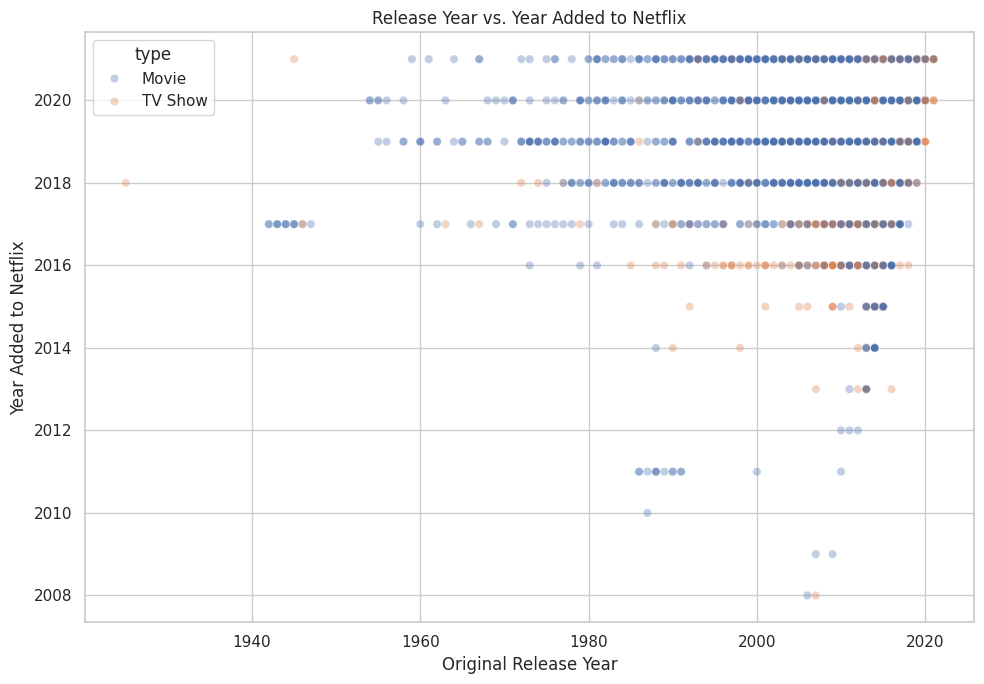

In [28]:
scatter_data = netflix.dropna(
    subset=["release_year", "year_added"]
)
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=scatter_data,
    x="release_year",
    y="year_added",
    hue="type",
    alpha=0.35
)
plt.title("Release Year vs. Year Added to Netflix")
plt.xlabel("Original Release Year")
plt.ylabel("Year Added to Netflix")
plt.tight_layout()
plt.show()



Finding

Titles near the diagonal were added to Netflix relatively close to their original release date. Titles farther from the diagonal represent older content that was added later.
This demonstrates that the catalog contains a mixture of recently released titles and older library content.

In [29]:
summary = pd.DataFrame({
    "Metric": [
        "Total Titles",
        "Movies",
        "TV Shows",
        "Median Movie Duration",
        "Median TV Show Seasons",
        "Median Content Age When Added",
        "Movie Duration Outliers"
    ],
    "Value": [
        len(netflix),
        (netflix["type"] == "Movie").sum(),
        (netflix["type"] == "TV Show").sum(),
        f"{netflix['movie_minutes'].median():.0f} minutes",
        f"{netflix['tv_seasons'].median():.0f} seasons",
        f"{netflix['content_age_at_addition'].median():.0f} years",
        movie_data["duration_outlier"].sum()
    ]
})
summary


,Metric,Value
0,Total Titles,8807
1,Movies,6131
2,TV Shows,2676
3,Median Movie Duration,98 minutes
4,Median TV Show Seasons,1 seasons
5,Median Content Age When Added,1 years
6,Movie Duration Outliers,450



Key Findings

The analysis provides several insights into the Netflix catalog:
1. Movies dominate the catalog. Movies represent a substantially larger portion of titles than TV shows.
2. Netflix expanded its catalog rapidly. The number of titles added increased significantly during the later years represented in the dataset.
3. Content is internationally diverse but geographically concentrated. Several countries account for a large portion of the catalog, particularly the United States and India.
4. Certain genres dominate the catalog. Drama, comedy, and international-content categories appear frequently.
5. Mature and teenage audiences are strongly represented. Ratings such as TV-MA and TV-14 occur frequently in the dataset.
6. Movie duration contains legitimate outliers. Several unusually short and long movies were identified using the IQR method. They were retained because they may represent valid content rather than data errors.
7. Netflix contains both new and older content. The comparison between release year and year added indicates that Netflix includes both recently released titles and older library content.

Recommendations

Based on the analysis:
• Movies and TV shows should be analyzed separately when studying duration because their duration measures represent different concepts.
• Individual genres should be separated when deeper genre-level analysis is required.
• Multi-country titles should be considered carefully in geographic analysis.
• Future analysis could combine catalog data with viewer ratings, popularity, or engagement data to investigate audience behavior.

Limitations

This analysis has several limitations:
• The dataset represents a historical snapshot and not the current Netflix catalog.
• It contains catalog information rather than actual viewer behavior.
• Some descriptive attributes contain missing values.
• Titles can have multiple countries and genres.
• The final year represented in the dataset may be incomplete.
Overall, the project demonstrates how data cleaning, descriptive statistics, outlier detection, and visualization can be combined to turn a raw entertainment dataset into meaningful insights.